# Assignment 2: Brawl Stars Brawler Classification + SOTA
10 classes: Bull, Leon, Shelly, Spike (from A1) + 8-Bit, Bibi, Bo, Emz, Frank, Miko (new).
Every class: 20 original screenshots + 180 augmented copies (`augment.py`) = 200 images.
New screenshots were cropped to 256×256 around the brawler with `crop_new.py` (the brawler name on the screen is cut away).

## 1. Data loading and split
Same split as in A1: the **originals** are split 12 / 4 / 4, copies go to the same part as their original.
Same seed (42) and same order, so the 4 old classes get exactly the same train / val / test images as in A1.

In [1]:
import random

DATA = 'dataset'
CLASSES = ['bull', 'leon', 'shelly', 'spike', '8-bit', 'bibi', 'bo', 'emz', 'frank', 'miko']

random.seed(42)
train, val, test = [], [], []

for label in range(len(CLASSES)):
    name = CLASSES[label]
    numbers = list(range(1, 21))
    random.shuffle(numbers)

    for i in numbers[:12]:
        train.append((f'{DATA}/{name}/{name}_{i:03d}.jpg', label))
        first = 21 + (i - 1) * 9
        for n in range(first, first + 9):
            train.append((f'{DATA}/{name}/{name}_{n:03d}.jpg', label))

    for i in numbers[12:16]:
        val.append((f'{DATA}/{name}/{name}_{i:03d}.jpg', label))
    for i in numbers[16:]:
        test.append((f'{DATA}/{name}/{name}_{i:03d}.jpg', label))

print('train:', len(train), 'val:', len(val), 'test:', len(test))

train: 1200 val: 40 test: 40


One original screenshot of every class:

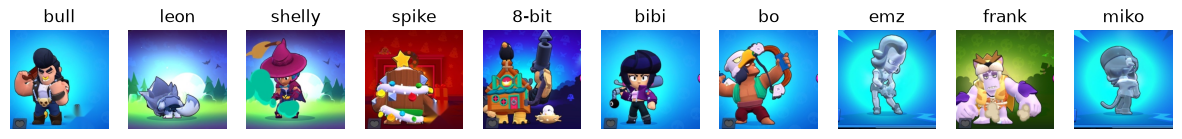

In [2]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(15, 3.5))
for label in range(len(CLASSES)):
    name = CLASSES[label]
    plt.subplot(1, len(CLASSES), label + 1)
    plt.imshow(Image.open(f'{DATA}/{name}/{name}_001.jpg'))
    plt.title(name)
    plt.axis('off')
plt.show()

## 2. Normalization and PyTorch preparation
Same as A1: image → 224×224 → tensor (values 0–1) → normalization with ImageNet mean and std. Batches of 32.

In [3]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from torchvision import transforms

prepare = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def to_dataset(items):
    images = []
    labels = []
    for path, label in items:
        img = Image.open(path).convert('RGB')
        images.append(prepare(img))
        labels.append(label)
    return TensorDataset(torch.stack(images), torch.tensor(labels))

train_loader = DataLoader(to_dataset(train), batch_size=32, shuffle=True)
val_loader = DataLoader(to_dataset(val), batch_size=32)
test_loader = DataLoader(to_dataset(test), batch_size=32)

images, labels = next(iter(train_loader))
print('batch shape:', images.shape)

batch shape: torch.Size([32, 3, 224, 224])


## 3. Baselines from A1: simple CNN and ResNet18
The same two models as in A1, only the last layer now has 10 outputs instead of 4.
We train them again on the 10-class dataset, so the comparison with the SOTA models is fair.

In [4]:
from torch import nn
from torchvision import models

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

def make_cnn():
    torch.manual_seed(42)
    model = nn.Sequential(
        nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(64 * 28 * 28, len(CLASSES)),
    )
    return model.to(device)

def make_resnet():
    torch.manual_seed(42)
    model = models.resnet18(weights='IMAGENET1K_V1')
    model.fc = nn.Linear(512, len(CLASSES))
    return model.to(device)

device: cuda


## 4. Training loop
Same functions as in A1. After each epoch: training loss, train accuracy and validation accuracy.

In [5]:
def accuracy(model, loader):
    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in loader:
            out = model(images.to(device))
            correct += (out.argmax(1).cpu() == labels).sum().item()
    return correct / len(loader.dataset)

def train_model(model, train_loader, val_loader, epochs, lr, show=True):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses, train_accs, val_accs = [], [], []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            out = model(images)
            loss = loss_fn(out, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(labels)

        losses.append(total_loss / len(train_loader.dataset))
        train_accs.append(accuracy(model, train_loader))
        val_accs.append(accuracy(model, val_loader))
        if show:
            print(f'epoch {epoch + 1}: loss {losses[-1]:.3f}, train {train_accs[-1]:.2f}, val {val_accs[-1]:.2f}')

    return losses, train_accs, val_accs

def plot_history(losses, train_accs, val_accs, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
    ax1.plot(losses)
    ax1.set_title(f'{title}: loss')
    ax1.set_xlabel('epoch')
    ax2.plot(train_accs, label='train')
    ax2.plot(val_accs, label='val')
    ax2.set_title(f'{title}: accuracy')
    ax2.set_xlabel('epoch')
    ax2.set_ylim(0, 1.05)
    ax2.legend()
    plt.show()

Trained models are saved to the `saved/` folder. If the file already exists, the model is loaded instead of trained again,
so re-running the notebook is fast. Delete the file in `saved/` to train the model again.

Simple CNN loaded from saved/


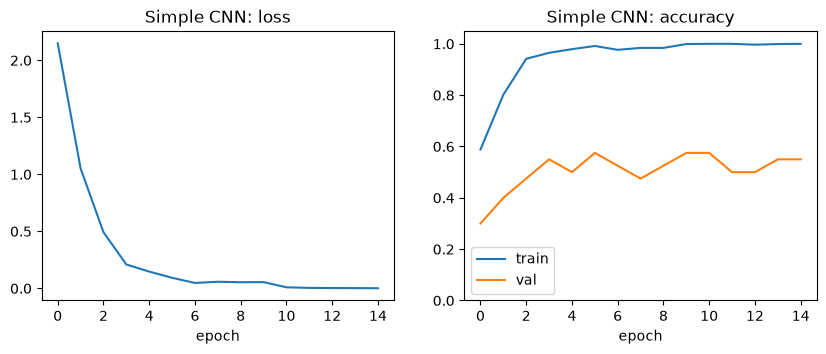

In [6]:
import os
os.makedirs('saved', exist_ok=True)

simple_cnn = make_cnn()
if os.path.exists('saved/cnn.pt'):
    simple_cnn.load_state_dict(torch.load('saved/cnn.pt'))
    cnn_history = torch.load('saved/cnn_history.pt')
    print('Simple CNN loaded from saved/')
else:
    cnn_history = train_model(simple_cnn, train_loader, val_loader, epochs=15, lr=0.001)
    torch.save(simple_cnn.state_dict(), 'saved/cnn.pt')
    torch.save(cnn_history, 'saved/cnn_history.pt')
plot_history(*cnn_history, 'Simple CNN')

ResNet18 loaded from saved/


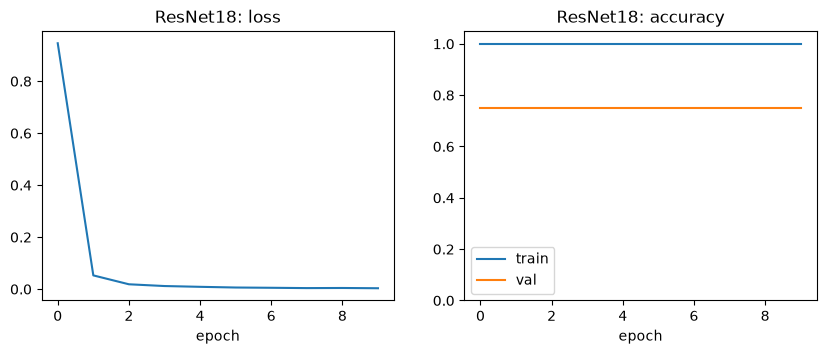

In [7]:
resnet = make_resnet()
if os.path.exists('saved/resnet18.pt'):
    resnet.load_state_dict(torch.load('saved/resnet18.pt'))
    resnet_history = torch.load('saved/resnet18_history.pt')
    print('ResNet18 loaded from saved/')
else:
    resnet_history = train_model(resnet, train_loader, val_loader, epochs=10, lr=0.0001)
    torch.save(resnet.state_dict(), 'saved/resnet18.pt')
    torch.save(resnet_history, 'saved/resnet18_history.pt')
plot_history(*resnet_history, 'ResNet18')

## 5. Test evaluation
Test = 40 originals (4 per class) that the models never saw. New metrics compared to A1:
- **macro-F1** — F1 of every class, then the simple average (every class counts the same);
- **top-5 accuracy** — the true class is among the 5 classes with the highest score.

Simple CNN
accuracy: 0.575
macro-F1: 0.545
top-5:    0.85
              precision    recall  f1-score   support

        bull      0.500     0.500     0.500         4
        leon      0.500     0.500     0.500         4
      shelly      0.571     1.000     0.727         4
       spike      0.667     0.500     0.571         4
       8-bit      1.000     0.500     0.667         4
        bibi      0.200     0.250     0.222         4
          bo      0.000     0.000     0.000         4
         emz      0.667     0.500     0.571         4
       frank      0.667     1.000     0.800         4
        miko      0.800     1.000     0.889         4

    accuracy                          0.575        40
   macro avg      0.557     0.575     0.545        40
weighted avg      0.557     0.575     0.545        40



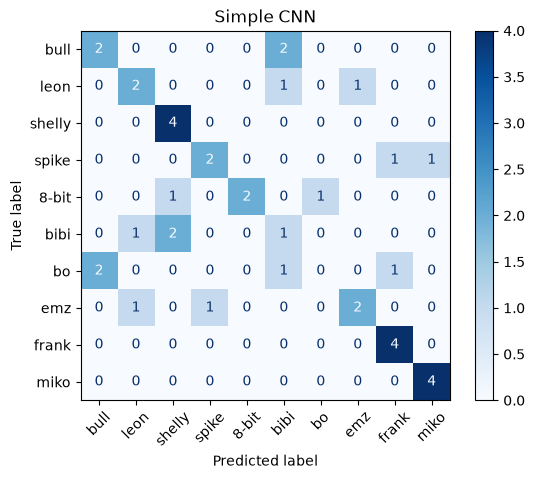

ResNet18
accuracy: 0.875
macro-F1: 0.872
top-5:    1.0
              precision    recall  f1-score   support

        bull      1.000     0.750     0.857         4
        leon      1.000     1.000     1.000         4
      shelly      1.000     1.000     1.000         4
       spike      1.000     1.000     1.000         4
       8-bit      1.000     1.000     1.000         4
        bibi      0.667     0.500     0.571         4
          bo      1.000     0.750     0.857         4
         emz      0.667     1.000     0.800         4
       frank      0.800     1.000     0.889         4
        miko      0.750     0.750     0.750         4

    accuracy                          0.875        40
   macro avg      0.888     0.875     0.872        40
weighted avg      0.888     0.875     0.872        40



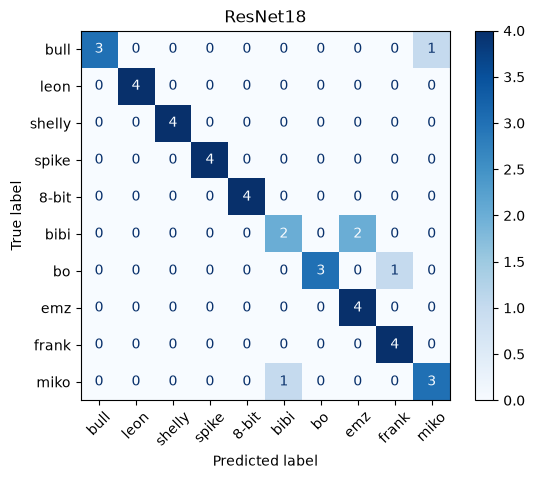

In [8]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

def predict(model, loader):
    model.eval()
    true, preds, in_top5 = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            out = model(images.to(device)).cpu()
            preds += out.argmax(1).tolist()
            true += labels.tolist()
            top5 = out.topk(5, dim=1).indices
            for j in range(len(labels)):
                in_top5.append(labels[j].item() in top5[j].tolist())
    return true, preds, in_top5

for model, title in [(simple_cnn, 'Simple CNN'), (resnet, 'ResNet18')]:
    true, preds, in_top5 = predict(model, test_loader)
    print(title)
    print('accuracy:', round(accuracy(model, test_loader), 3))
    print('macro-F1:', round(f1_score(true, preds, average='macro'), 3))
    print('top-5:   ', round(sum(in_top5) / len(in_top5), 3))
    print(classification_report(true, preds, target_names=CLASSES, digits=3, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(true, preds), display_labels=CLASSES).plot(cmap='Blues', xticks_rotation=45)
    plt.title(title)
    plt.show()

## 6. Cross-validation (5 folds)
A test of 40 images is still small: one mistake = 2.5%. Like in A1, the 20 originals of every class are split into 5 groups of 4.
5 times: one group is the test, the other 16 originals + their copies are the training set. Every one of the 200 originals is tested exactly once.

`cv_split(k)` builds the train and test lists of fold `k` (we will use it again for the SOTA models).
The cross-validation results are saved to `saved/cv_baselines.json`, so it runs only once.

In [9]:
import json
import numpy as np

random.seed(42)
order = {}
for name in CLASSES:
    numbers = list(range(1, 21))
    random.shuffle(numbers)
    order[name] = numbers

def cv_split(k):
    cv_train, cv_test = [], []
    for label in range(len(CLASSES)):
        name = CLASSES[label]
        for i in order[name]:
            if i in order[name][k * 4:k * 4 + 4]:
                cv_test.append((f'{DATA}/{name}/{name}_{i:03d}.jpg', label))
            else:
                cv_train.append((f'{DATA}/{name}/{name}_{i:03d}.jpg', label))
                first = 21 + (i - 1) * 9
                for n in range(first, first + 9):
                    cv_train.append((f'{DATA}/{name}/{name}_{n:03d}.jpg', label))
    return cv_train, cv_test

In [10]:
if os.path.exists('saved/cv_baselines.json'):
    with open('saved/cv_baselines.json') as f:
        cv = json.load(f)
    print('cross-validation results loaded from saved/')
else:
    cv = {'cnn_acc': [], 'cnn_f1': [], 'resnet_acc': [], 'resnet_f1': [], 'mistakes': []}
    for k in range(5):
        cv_train, cv_test = cv_split(k)
        cv_train_loader = DataLoader(to_dataset(cv_train), batch_size=32, shuffle=True)
        cv_test_loader = DataLoader(to_dataset(cv_test), batch_size=32)

        cnn = make_cnn()
        train_model(cnn, cv_train_loader, cv_test_loader, epochs=15, lr=0.001, show=False)
        true, preds, in_top5 = predict(cnn, cv_test_loader)
        cv['cnn_acc'].append(accuracy(cnn, cv_test_loader))
        cv['cnn_f1'].append(f1_score(true, preds, average='macro'))

        res = make_resnet()
        train_model(res, cv_train_loader, cv_test_loader, epochs=10, lr=0.0001, show=False)
        true, preds, in_top5 = predict(res, cv_test_loader)
        cv['resnet_acc'].append(accuracy(res, cv_test_loader))
        cv['resnet_f1'].append(f1_score(true, preds, average='macro'))
        for j in range(len(cv_test)):
            if preds[j] != true[j]:
                cv['mistakes'].append((cv_test[j][0], CLASSES[preds[j]]))

        print(f"fold {k + 1}: simple CNN {cv['cnn_acc'][-1]:.3f}, ResNet18 {cv['resnet_acc'][-1]:.3f}")
    with open('saved/cv_baselines.json', 'w') as f:
        json.dump(cv, f)

print(f"Simple CNN: accuracy {np.mean(cv['cnn_acc']):.3f} ± {np.std(cv['cnn_acc']):.3f}, macro-F1 {np.mean(cv['cnn_f1']):.3f} ± {np.std(cv['cnn_f1']):.3f}")
print(f"ResNet18:   accuracy {np.mean(cv['resnet_acc']):.3f} ± {np.std(cv['resnet_acc']):.3f}, macro-F1 {np.mean(cv['resnet_f1']):.3f} ± {np.std(cv['resnet_f1']):.3f}")

cross-validation results loaded from saved/
Simple CNN: accuracy 0.730 ± 0.048, macro-F1 0.724 ± 0.049
ResNet18:   accuracy 0.935 ± 0.044, macro-F1 0.931 ± 0.045


## 7. Error analysis
All originals that ResNet18 got wrong during cross-validation (title: true class -> predicted class).

ResNet18 mistakes: 13 of 200


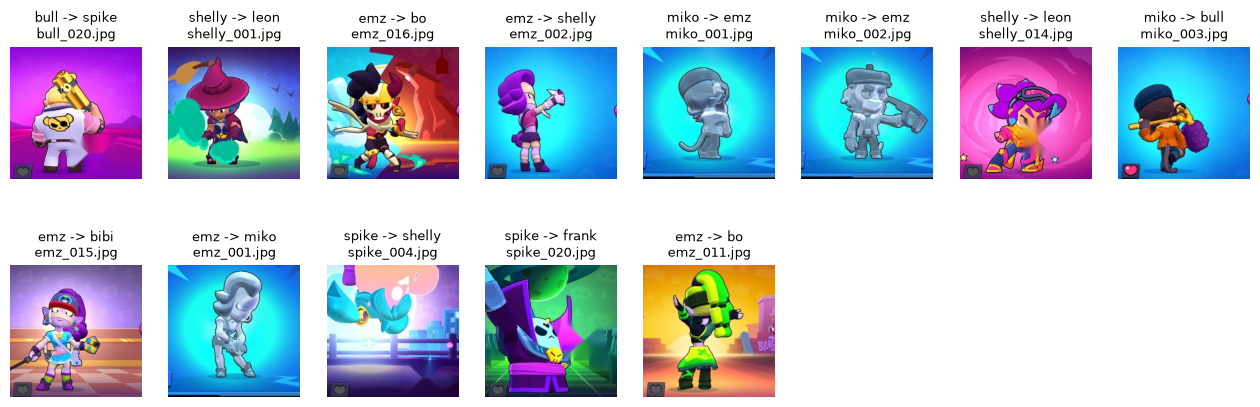

In [11]:
mistakes = cv['mistakes']
print('ResNet18 mistakes:', len(mistakes), 'of 200')

rows = (len(mistakes) + 7) // 8
plt.figure(figsize=(16, 2.6 * rows))
for j in range(len(mistakes)):
    path, pred = mistakes[j]
    true_name = path.split('/')[1]
    file_name = path.split('/')[2]
    plt.subplot(rows, 8, j + 1)
    plt.imshow(Image.open(path))
    plt.title(f'{true_name} -> {pred}\n{file_name}', fontsize=9)
    plt.axis('off')
plt.show()

## 8. SOTA #1: DINOv2
**DINOv2** (Meta, 2023) is a Vision Transformer (ViT-S/14, 22M parameters) trained **without labels** on 142M images (self-supervised).
It turns an image into a vector of 384 numbers (an *embedding*). Similar images get similar vectors.
We use it in 3 ways, from the simplest to the strongest:
1. **kNN** — no training at all: a test image gets the class of the most similar train images;
2. **linear probe** — DINOv2 is frozen, we train only one linear layer on top;
3. **fine-tuning** — we also train the last 4 of the 12 transformer blocks with a very small learning rate.

First, every image goes through frozen DINOv2 once, the 384 numbers are saved to `saved/dino_features.pt`.

In [12]:
import warnings
warnings.filterwarnings('ignore', message='xFormers')

dino = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14', verbose=False).to(device)
dino.eval()
print('DINOv2 ViT-S/14, parameters:', sum(p.numel() for p in dino.parameters()))

if os.path.exists('saved/dino_features.pt'):
    features = torch.load('saved/dino_features.pt')
    print('features loaded from saved/')
else:
    features = {}
    with torch.no_grad():
        for name in CLASSES:
            for i in range(1, 201):
                path = f'{DATA}/{name}/{name}_{i:03d}.jpg'
                img = prepare(Image.open(path).convert('RGB')).unsqueeze(0).to(device)
                features[path] = dino(img)[0].cpu()
    torch.save(features, 'saved/dino_features.pt')
print('images with features:', len(features), ', one feature vector:', features[train[0][0]].shape)

DINOv2 ViT-S/14, parameters: 22056576


features loaded from saved/
images with features: 2000 , one feature vector: torch.Size([384])


In [13]:
def to_features(items):
    x, y = [], []
    for path, label in items:
        x.append(features[path])
        y.append(label)
    return torch.stack(x), torch.tensor(y)

train_x, train_y = to_features(train)
val_x, val_y = to_features(val)
test_x, test_y = to_features(test)
print('train features:', train_x.shape, 'test features:', test_x.shape)

train features: torch.Size([1200, 384]) test features: torch.Size([40, 384])


### 8.1 kNN on DINOv2 features (no training)
**Cosine similarity** of two vectors = how much they point in the same direction (1 = the same, 0 = unrelated).
For every test image we take the `k` most similar train images, and they vote for the class.
`k` is chosen on **validation** (never on test).

In [14]:
def knn_predict(train_x, train_y, test_x, k):
    train_x = nn.functional.normalize(train_x, dim=1)
    test_x = nn.functional.normalize(test_x, dim=1)
    similarity = test_x @ train_x.T
    nearest = similarity.topk(k, dim=1).indices
    preds = []
    for row in nearest:
        votes = torch.bincount(train_y[row], minlength=len(CLASSES))
        preds.append(votes.argmax().item())
    return preds

best_k, best_val = 1, 0
for k in [1, 5, 10]:
    val_preds = knn_predict(train_x, train_y, val_x, k)
    val_acc = (torch.tensor(val_preds) == val_y).float().mean().item()
    print(f'k = {k}: validation accuracy {val_acc:.3f}')
    if val_acc > best_val:
        best_k, best_val = k, val_acc
print('chosen k:', best_k)

k = 1: validation accuracy 0.750
k = 5: validation accuracy 0.725
k = 10: validation accuracy 0.750
chosen k: 1


**Retrieval: precision@k.** Query = a test image, database = the 120 train **originals** (the copies are almost the same pictures, they would fill the top-5).
P@k = share of the `k` most similar database images that have the same brawler. The same search gives the *nearest-neighbors gallery* for the app.

In [15]:
train_orig = []
for path, label in train:
    if int(path[-7:-4]) <= 20:
        train_orig.append((path, label))
orig_x, orig_y = to_features(train_orig)

def precision_at_k(base_x, base_y, query_x, query_y, k):
    base_x = nn.functional.normalize(base_x, dim=1)
    query_x = nn.functional.normalize(query_x, dim=1)
    nearest = (query_x @ base_x.T).topk(k, dim=1).indices
    correct = 0
    for j in range(len(query_y)):
        correct += (base_y[nearest[j]] == query_y[j]).sum().item()
    return correct / (len(query_y) * k)

print('database:', len(train_orig), 'originals')
for k in [1, 5]:
    print(f'P@{k}: {precision_at_k(orig_x, orig_y, test_x, test_y, k):.3f}')

database: 120 originals
P@1: 0.775
P@5: 0.465


### 8.2 Linear probe
DINOv2 stays frozen, only `nn.Linear(384, 10)` is trained on the saved features. It takes seconds,
and we reuse the same `train_model` function as for the baselines.

after 30 epochs: loss 0.010, train 1.00, val 0.78


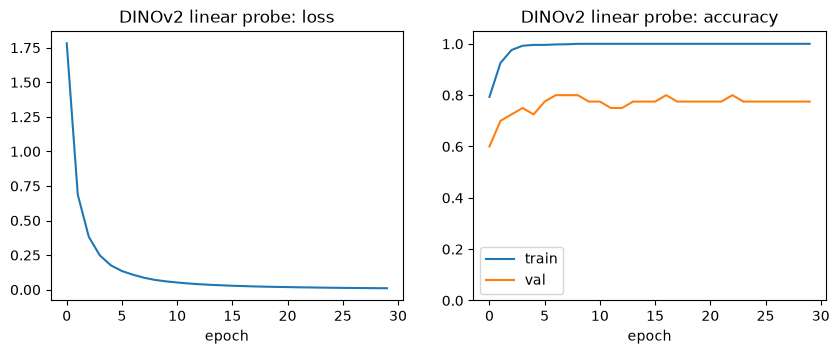

In [16]:
feat_train_loader = DataLoader(TensorDataset(train_x, train_y), batch_size=32, shuffle=True)
feat_val_loader = DataLoader(TensorDataset(val_x, val_y), batch_size=32)
feat_test_loader = DataLoader(TensorDataset(test_x, test_y), batch_size=32)

torch.manual_seed(42)
linear = nn.Linear(384, len(CLASSES)).to(device)
linear_history = train_model(linear, feat_train_loader, feat_val_loader, epochs=30, lr=0.001, show=False)
print(f'after 30 epochs: loss {linear_history[0][-1]:.3f}, train {linear_history[1][-1]:.2f}, val {linear_history[2][-1]:.2f}')
plot_history(*linear_history, 'DINOv2 linear probe')

### 8.3 Fine-tuning the last 4 blocks
Model = DINOv2 + linear layer. The first 8 blocks stay frozen (they already know general shapes and textures,
and training all 12 blocks does not fit into the 4 GB of our GPU). The last 4 blocks and the head are trained with lr = 0.00001.
The head starts from the trained linear probe, not from random numbers (*LP-FT*): random head + training the backbone
can destroy the good DINOv2 features in the first epochs.

trainable parameters: 7105546
DINOv2 fine-tuned loaded from saved/


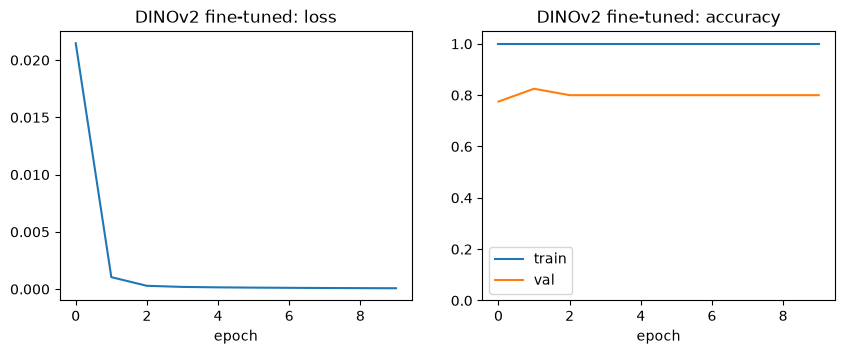

In [17]:
import copy

def make_dino_ft(head):
    torch.manual_seed(42)
    backbone = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14', verbose=False)
    for p in backbone.parameters():
        p.requires_grad = False
    for block in backbone.blocks[-4:]:
        for p in block.parameters():
            p.requires_grad = True
    for p in backbone.norm.parameters():
        p.requires_grad = True
    model = nn.Sequential(backbone, copy.deepcopy(head))
    return model.to(device)

dino_ft = make_dino_ft(linear)
trainable = 0
for p in dino_ft.parameters():
    if p.requires_grad:
        trainable += p.numel()
print('trainable parameters:', trainable)

if os.path.exists('saved/dino_ft.pt'):
    dino_ft.load_state_dict(torch.load('saved/dino_ft.pt'))
    ft_history = torch.load('saved/dino_ft_history.pt')
    print('DINOv2 fine-tuned loaded from saved/')
else:
    ft_history = train_model(dino_ft, train_loader, val_loader, epochs=10, lr=0.00001)
    torch.save(dino_ft.state_dict(), 'saved/dino_ft.pt')
    torch.save(ft_history, 'saved/dino_ft_history.pt')
plot_history(*ft_history, 'DINOv2 fine-tuned')

### 8.4 Test evaluation of DINOv2 (the same 40 test images)

DINOv2 kNN (k = 1)
accuracy: 0.8
macro-F1: 0.787

DINOv2 linear probe
accuracy: 0.85
macro-F1: 0.851
top-5:    0.975
              precision    recall  f1-score   support

        bull      0.800     1.000     0.889         4
        leon      0.800     1.000     0.889         4
      shelly      1.000     0.750     0.857         4
       spike      1.000     0.750     0.857         4
       8-bit      1.000     1.000     1.000         4
        bibi      0.667     0.500     0.571         4
          bo      1.000     0.750     0.857         4
         emz      0.571     1.000     0.727         4
       frank      1.000     0.750     0.857         4
        miko      1.000     1.000     1.000         4

    accuracy                          0.850        40
   macro avg      0.884     0.850     0.851        40
weighted avg      0.884     0.850     0.851        40



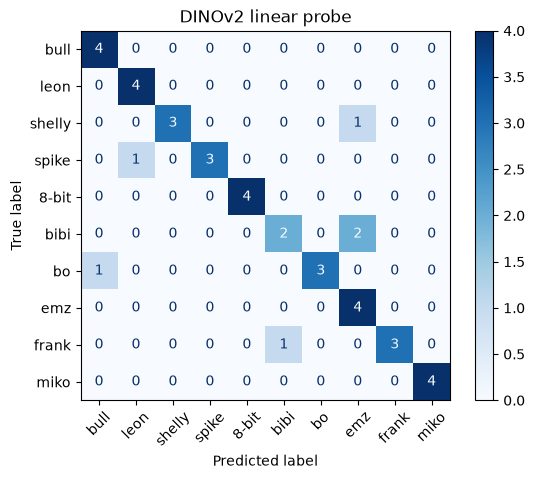

DINOv2 fine-tuned
accuracy: 0.9
macro-F1: 0.901
top-5:    1.0
              precision    recall  f1-score   support

        bull      1.000     1.000     1.000         4
        leon      0.800     1.000     0.889         4
      shelly      1.000     0.750     0.857         4
       spike      1.000     0.750     0.857         4
       8-bit      1.000     1.000     1.000         4
        bibi      1.000     0.750     0.857         4
          bo      1.000     0.750     0.857         4
         emz      0.667     1.000     0.800         4
       frank      0.800     1.000     0.889         4
        miko      1.000     1.000     1.000         4

    accuracy                          0.900        40
   macro avg      0.927     0.900     0.901        40
weighted avg      0.927     0.900     0.901        40



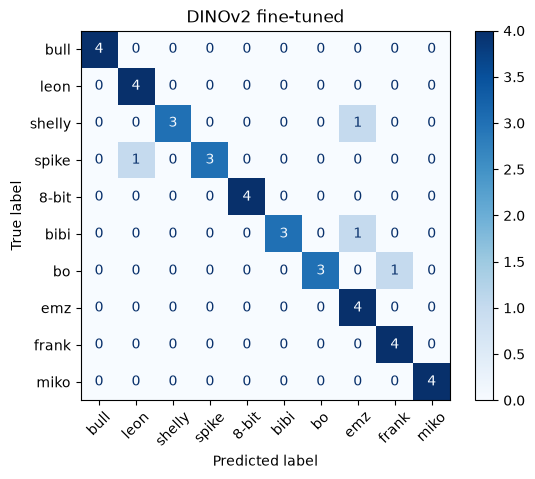

In [18]:
knn_preds = knn_predict(train_x, train_y, test_x, best_k)
print(f'DINOv2 kNN (k = {best_k})')
print('accuracy:', round((torch.tensor(knn_preds) == test_y).float().mean().item(), 3))
print('macro-F1:', round(f1_score(test_y.tolist(), knn_preds, average='macro'), 3))
print()

for model, loader, title in [(linear, feat_test_loader, 'DINOv2 linear probe'), (dino_ft, test_loader, 'DINOv2 fine-tuned')]:
    true, preds, in_top5 = predict(model, loader)
    print(title)
    print('accuracy:', round(accuracy(model, loader), 3))
    print('macro-F1:', round(f1_score(true, preds, average='macro'), 3))
    print('top-5:   ', round(sum(in_top5) / len(in_top5), 3))
    print(classification_report(true, preds, target_names=CLASSES, digits=3, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(true, preds), display_labels=CLASSES).plot(cmap='Blues', xticks_rotation=45)
    plt.title(title)
    plt.show()

## 9. Cross-validation of DINOv2 (the same 5 folds as the baselines)
kNN and linear probe use the saved features, so they are fast. Fine-tuning is trained from DINOv2 again in every fold.
Results are saved to `saved/cv_dino.json`.

In [19]:
if os.path.exists('saved/cv_dino.json'):
    with open('saved/cv_dino.json') as f:
        cv_dino = json.load(f)
    print('cross-validation results loaded from saved/')
else:
    cv_dino = {'knn_acc': [], 'knn_f1': [], 'linear_acc': [], 'linear_f1': [], 'ft_acc': [], 'ft_f1': [], 'mistakes': []}
    for k in range(5):
        cv_train, cv_test = cv_split(k)
        tr_x, tr_y = to_features(cv_train)
        te_x, te_y = to_features(cv_test)

        preds = knn_predict(tr_x, tr_y, te_x, best_k)
        cv_dino['knn_acc'].append((torch.tensor(preds) == te_y).float().mean().item())
        cv_dino['knn_f1'].append(f1_score(te_y.tolist(), preds, average='macro'))

        torch.manual_seed(42)
        lin = nn.Linear(384, len(CLASSES)).to(device)
        tr_loader = DataLoader(TensorDataset(tr_x, tr_y), batch_size=32, shuffle=True)
        te_loader = DataLoader(TensorDataset(te_x, te_y), batch_size=32)
        train_model(lin, tr_loader, te_loader, epochs=30, lr=0.001, show=False)
        true, preds, in_top5 = predict(lin, te_loader)
        cv_dino['linear_acc'].append(accuracy(lin, te_loader))
        cv_dino['linear_f1'].append(f1_score(true, preds, average='macro'))

        ft = make_dino_ft(lin)
        cv_train_loader = DataLoader(to_dataset(cv_train), batch_size=32, shuffle=True)
        cv_test_loader = DataLoader(to_dataset(cv_test), batch_size=32)
        train_model(ft, cv_train_loader, cv_test_loader, epochs=10, lr=0.00001, show=False)
        true, preds, in_top5 = predict(ft, cv_test_loader)
        cv_dino['ft_acc'].append(accuracy(ft, cv_test_loader))
        cv_dino['ft_f1'].append(f1_score(true, preds, average='macro'))
        for j in range(len(cv_test)):
            if preds[j] != true[j]:
                cv_dino['mistakes'].append((cv_test[j][0], CLASSES[preds[j]]))

        print(f"fold {k + 1}: kNN {cv_dino['knn_acc'][-1]:.3f}, linear {cv_dino['linear_acc'][-1]:.3f}, fine-tuned {cv_dino['ft_acc'][-1]:.3f}")
    with open('saved/cv_dino.json', 'w') as f:
        json.dump(cv_dino, f)

for short, title in [('knn', 'DINOv2 kNN'), ('linear', 'DINOv2 linear probe'), ('ft', 'DINOv2 fine-tuned')]:
    acc, f1 = cv_dino[short + '_acc'], cv_dino[short + '_f1']
    print(f'{title}: accuracy {np.mean(acc):.3f} ± {np.std(acc):.3f}, macro-F1 {np.mean(f1):.3f} ± {np.std(f1):.3f}')

cross-validation results loaded from saved/
DINOv2 kNN: accuracy 0.830 ± 0.053, macro-F1 0.822 ± 0.060
DINOv2 linear probe: accuracy 0.845 ± 0.062, macro-F1 0.845 ± 0.061
DINOv2 fine-tuned: accuracy 0.870 ± 0.048, macro-F1 0.868 ± 0.049


Mistakes of the fine-tuned DINOv2 during cross-validation (compare with the ResNet18 mistakes in section 7):

DINOv2 fine-tuned mistakes: 26 of 200


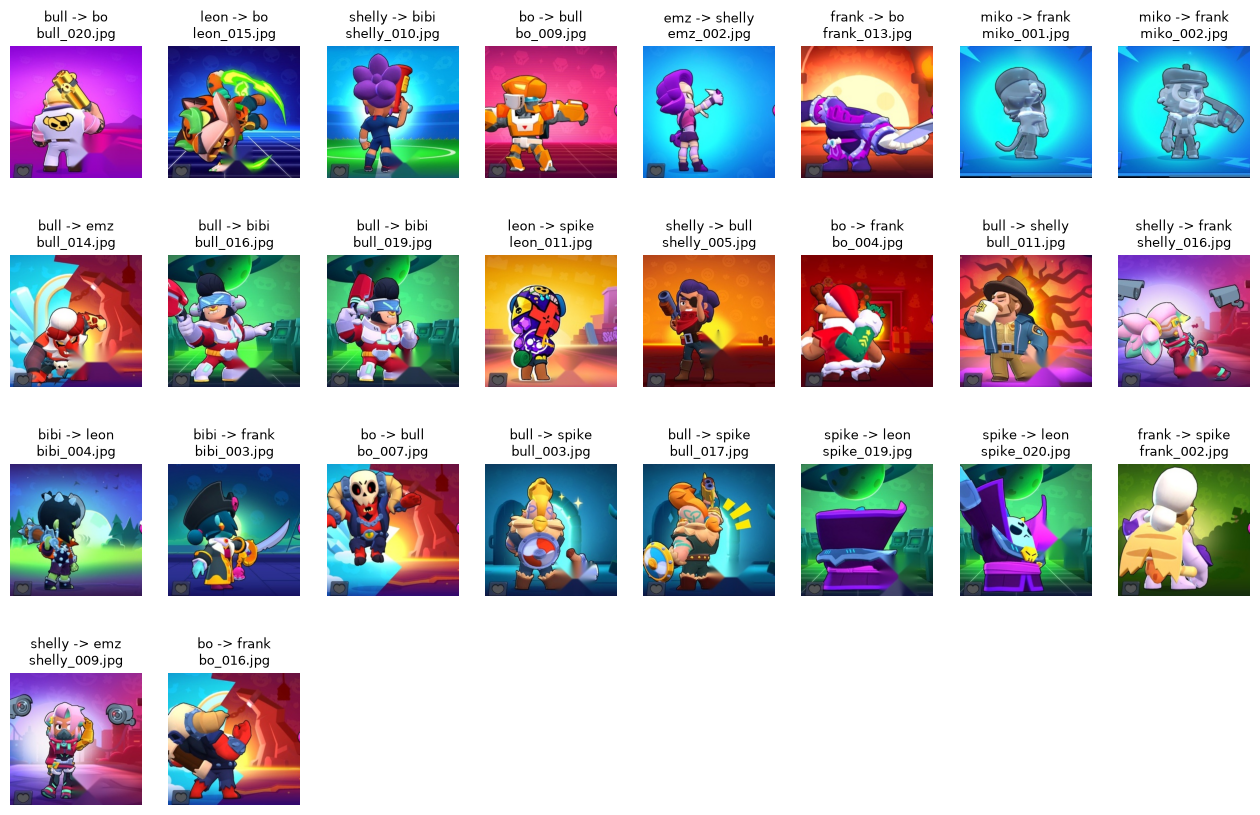

In [20]:
mistakes = cv_dino['mistakes']
print('DINOv2 fine-tuned mistakes:', len(mistakes), 'of 200')

rows = (len(mistakes) + 7) // 8
plt.figure(figsize=(16, 2.6 * rows))
for j in range(len(mistakes)):
    path, pred = mistakes[j]
    true_name = path.split('/')[1]
    file_name = path.split('/')[2]
    plt.subplot(rows, 8, j + 1)
    plt.imshow(Image.open(path))
    plt.title(f'{true_name} -> {pred}\n{file_name}', fontsize=9)
    plt.axis('off')
plt.show()

## 10. Ablation: how many screenshots per brawler does DINOv2 need?
We keep only 1, 2, 4, 8 or all 16 training originals per class (+ their copies) in every cross-validation fold,
and check kNN and linear probe on the full test part of the fold. It uses the saved features, so it takes seconds.

 1 originals per class: kNN macro-F1 0.156, linear probe macro-F1 0.154


 2 originals per class: kNN macro-F1 0.285, linear probe macro-F1 0.335


 4 originals per class: kNN macro-F1 0.507, linear probe macro-F1 0.528


 8 originals per class: kNN macro-F1 0.658, linear probe macro-F1 0.691


16 originals per class: kNN macro-F1 0.822, linear probe macro-F1 0.845


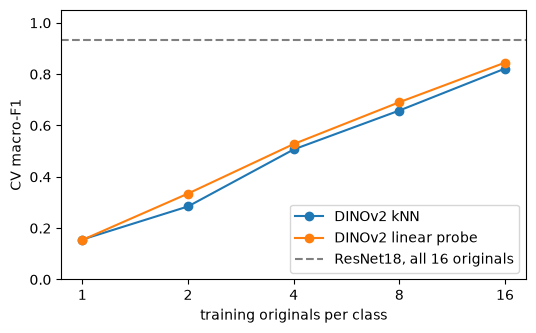

In [21]:
def original_number(path):
    n = int(path[-7:-4])
    if n <= 20:
        return n
    return (n - 21) // 9 + 1

shots_list = [1, 2, 4, 8, 16]
if os.path.exists('saved/ablation_shots.json'):
    with open('saved/ablation_shots.json') as f:
        ablation = json.load(f)
    print('ablation results loaded from saved/')
else:
    ablation = {'knn': [], 'linear': []}
    for shots in shots_list:
        knn_scores, linear_scores = [], []
        for k in range(5):
            cv_train, cv_test = cv_split(k)
            small = []
            for path, label in cv_train:
                name = CLASSES[label]
                train_numbers = []
                for i in order[name]:
                    if i not in order[name][k * 4:k * 4 + 4]:
                        train_numbers.append(i)
                if original_number(path) in train_numbers[:shots]:
                    small.append((path, label))
            tr_x, tr_y = to_features(small)
            te_x, te_y = to_features(cv_test)

            preds = knn_predict(tr_x, tr_y, te_x, best_k)
            knn_scores.append(f1_score(te_y.tolist(), preds, average='macro'))

            torch.manual_seed(42)
            lin = nn.Linear(384, len(CLASSES)).to(device)
            tr_loader = DataLoader(TensorDataset(tr_x, tr_y), batch_size=32, shuffle=True)
            te_loader = DataLoader(TensorDataset(te_x, te_y), batch_size=32)
            train_model(lin, tr_loader, te_loader, epochs=30, lr=0.001, show=False)
            true, preds, in_top5 = predict(lin, te_loader)
            linear_scores.append(f1_score(true, preds, average='macro'))
        ablation['knn'].append(np.mean(knn_scores))
        ablation['linear'].append(np.mean(linear_scores))
        print(f"{shots:2d} originals per class: kNN macro-F1 {ablation['knn'][-1]:.3f}, linear probe macro-F1 {ablation['linear'][-1]:.3f}")
    with open('saved/ablation_shots.json', 'w') as f:
        json.dump(ablation, f)

plt.figure(figsize=(6, 3.5))
plt.plot(shots_list, ablation['knn'], marker='o', label='DINOv2 kNN')
plt.plot(shots_list, ablation['linear'], marker='o', label='DINOv2 linear probe')
plt.axhline(np.mean(cv['resnet_f1']), color='gray', linestyle='--', label='ResNet18, all 16 originals')
plt.xscale('log', base=2)
plt.xticks(shots_list, shots_list)
plt.xlabel('training originals per class')
plt.ylabel('CV macro-F1')
plt.ylim(0, 1.05)
plt.legend()
plt.show()

## 11. Results table
**CPU latency**: one image (batch = 1) on the CPU, 10 warm-up runs and then 50 measured runs, mean ± std in milliseconds.
CPU, because the demo app must work on a computer without a GPU. kNN and linear probe use the same DINOv2 forward pass,
so they have the same latency as the fine-tuned model (+ less than 1 ms for the head).

In [22]:
import time
import platform

def cpu_latency(model):
    model = copy.deepcopy(model).cpu().eval()
    x = torch.randn(1, 3, 224, 224)
    times = []
    with torch.no_grad():
        for i in range(60):
            start = time.perf_counter()
            model(x)
            times.append((time.perf_counter() - start) * 1000)
    times = times[10:]
    return np.mean(times), np.std(times)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

print('CPU:', platform.processor(), '| threads:', torch.get_num_threads(), '| torch', torch.__version__)
latency = {}
for model, title in [(simple_cnn, 'Simple CNN'), (resnet, 'ResNet18'), (dino_ft, 'DINOv2')]:
    latency[title] = cpu_latency(model)
    print(f'{title}: {latency[title][0]:.1f} ± {latency[title][1]:.1f} ms')

CPU: AMD64 Family 23 Model 96 Stepping 1, AuthenticAMD | threads: 8 | torch 2.14.1+cu126


Simple CNN: 5.1 ± 0.5 ms


ResNet18: 26.0 ± 1.6 ms


DINOv2: 81.3 ± 11.4 ms


In [23]:
rows = [
    ('Simple CNN (A1)', cv['cnn_acc'], cv['cnn_f1'], 'Simple CNN', count_params(simple_cnn)),
    ('ResNet18 (A1)', cv['resnet_acc'], cv['resnet_f1'], 'ResNet18', count_params(resnet)),
    (f'DINOv2 kNN (k={best_k})', cv_dino['knn_acc'], cv_dino['knn_f1'], 'DINOv2', count_params(dino)),
    ('DINOv2 linear probe', cv_dino['linear_acc'], cv_dino['linear_f1'], 'DINOv2', count_params(dino_ft)),
    ('DINOv2 fine-tuned', cv_dino['ft_acc'], cv_dino['ft_f1'], 'DINOv2', count_params(dino_ft)),
]
print(f"{'Model':<22}{'CV accuracy':<17}{'CV macro-F1':<17}{'CPU latency, ms':<18}{'Params'}")
for title, acc, f1, lat, params in rows:
    print(f'{title:<22}{np.mean(acc):.3f} ± {np.std(acc):.3f}    {np.mean(f1):.3f} ± {np.std(f1):.3f}    '
          f'{latency[lat][0]:6.1f} ± {latency[lat][1]:<6.1f}    {params / 1e6:.1f}M')

Model                 CV accuracy      CV macro-F1      CPU latency, ms   Params
Simple CNN (A1)       0.730 ± 0.048    0.724 ± 0.049       5.1 ± 0.5       0.5M
ResNet18 (A1)         0.935 ± 0.044    0.931 ± 0.045      26.0 ± 1.6       11.2M
DINOv2 kNN (k=1)      0.830 ± 0.053    0.822 ± 0.060      81.3 ± 11.4      22.1M
DINOv2 linear probe   0.845 ± 0.062    0.845 ± 0.061      81.3 ± 11.4      22.1M
DINOv2 fine-tuned     0.870 ± 0.048    0.868 ± 0.049      81.3 ± 11.4      22.1M


---
# Разбор для защиты: что сделано, зачем и как это объяснить

## 0. Расширение датасета (до кода ноутбука)
- **Что:** к 4 бравлерам из A1 добавили 6 новых (8-Bit, Bibi, Bo, Emz, Frank, Miko), в каждом по 20 оригинальных скриншотов.
- **Зачем:** при 4 классах ResNet18 уже давал ~94%, улучшать почти некуда, а top-5 при 4 классах всегда равен 100%. С 10 классами задача сложнее, и сравнение baseline с SOTA становится осмысленным.
- **`crop_new.py`:** новые скриншоты — это весь экран телефона (1280×591), а на экране **написано имя бравлера**. Если оставить его, модель научится читать надпись, а не узнавать персонажа (это называется *shortcut*). Поэтому вырезаем квадрат вокруг персонажа (как в старых картинках, иконка сердечка в углу) и уменьшаем до 256×256. Три картинки (emz_001, miko_001, miko_002) — экран «Особая акция», для них отдельная рамка.
- **`augment.py`:** как в A1, 9 случайных копий каждого оригинала (поворот, масштаб, сдвиг, отражение, яркость/контраст, оттенок, размытие). В список просто дописаны новые имена. Проверили: старые 720 копий при повторном запуске получаются байт-в-байт такими же, значит данные A1 не изменились.
- **Синтетические (аугментированные) данные:** 1800 из 2000 картинок (90%) — аугментированные копии. Они есть **только в train**, в val и test только настоящие скриншоты.

## 1. Сплит (ячейка 1)
- Делим **оригиналы**: 12 в train, 4 в val, 4 в test на класс. Копии идут туда же, где их оригинал. Иначе в test попала бы копия того же скриншота, что и в train (почти тот же кадр). Это *утечка данных*, и точность была бы завышена.
- `first = 21 + (i - 1) * 9` — номер первой копии оригинала `i` (копии оригинала 1 — это 021–029, оригинала 2 — 030–038, …).
- Тот же `random.seed(42)` и те же 4 класса в начале списка → у старых классов те же test-картинки, что и в A1.

## 2. Подготовка картинок (ячейка 2)
- Resize до 224×224, перевод в тензор 0–1 и нормализация средним/std ImageNet: ResNet18 обучали на ImageNet именно с такой нормализацией.
- `TensorDataset` держит все картинки в памяти, поэтому эпоха идёт быстро.

## 3–4. Baseline-модели и обучение
- Те же две модели, что в A1. Изменилось только число выходов: **10 вместо 4** (`len(CLASSES)`). Модели A1 обучены на 4 классах, поэтому их нужно обучить заново, иначе сравнение с SOTA будет нечестным.
- Simple CNN: 3 блока conv → ReLU → max pool. После трёх пулингов 224 → 112 → 56 → 28, поэтому линейный слой получает `64 * 28 * 28` чисел.
- ResNet18: предобучен на ImageNet, последний слой заменён на `Linear(512, 10)`, дообучаем всю сеть с маленьким lr = 0.0001 (*transfer learning*).
- **Сохранение (`saved/`):** после обучения веса (`.pt`) и история обучения сохраняются. При повторном запуске срабатывает `if os.path.exists(...)`: модель загружается, а не обучается заново. Чтобы переобучить, достаточно удалить файл.
- **Кривые:** у Simple CNN train accuracy = 1.00, а val около 0.55, это сильное переобучение (модель запомнила train). У ResNet18 val = 0.75 уже после первой эпохи: предобученные признаки сразу хороши.

## 5. Оценка на test (40 оригиналов)
| Model | Accuracy | Macro-F1 | Top-5 |
|---|---|---|---|
| Simple CNN | 0.575 | 0.545 | 0.850 |
| ResNet18 | 0.875 | 0.872 | 1.000 |

- **Macro-F1** — F1 считается для каждого класса отдельно, потом берётся простое среднее. Каждый класс весит одинаково, поэтому плохой класс сразу виден. **Top-5** — правильный класс среди 5 самых вероятных.
- Confusion matrix ResNet18: ошибки в основном на Bibi (дважды путает с Emz) и Miko.
- **Важно:** test маленький, одна ошибка = 2.5%. Поэтому у ResNet18 val = 0.75, а test = 0.875: это разброс маленькой выборки. Главной оценкой берём cross-validation.

## 6. Cross-validation (5 фолдов, 200 оригиналов)
| Model | Accuracy (mean ± std) | Macro-F1 (mean ± std) |
|---|---|---|
| Simple CNN | 0.730 ± 0.048 | 0.724 ± 0.049 |
| ResNet18 | 0.935 ± 0.044 | 0.931 ± 0.045 |

- Каждый из 200 оригиналов один раз попадает в test, поэтому результат надёжнее, чем на 40 картинках. mean ± std — среднее и разброс по 5 фолдам.
- Если сравнивать с A1 (4 класса): ResNet18 почти не просел (0.938 → 0.935), а Simple CNN упал (0.800 → 0.730). Чем больше классов, тем сильнее помогает предобучение.
- `cv_split(k)` собирает train/test фолда `k`. Мы вынесли её в функцию, чтобы потом прогнать через те же фолды SOTA-модели. Результаты сохраняются в `saved/cv_baselines.json`.

## 7. Анализ ошибок ResNet18 (13 из 200)
- **Серебряные скины** (emz_001, miko_001, miko_002): все три — ошибки. Это серые фигуры без цвета на одинаковом синем фоне экрана «Особая акция», и модель путает Emz и Miko между собой. Значит, ResNet18 сильно опирается на **цвет**.
- **Emz — самый трудный класс:** 5 ошибок из 13. У неё очень разные по цвету и форме скины (см. картинки выше).
- **Те же ошибки, что в A1:** bull_020 (скин, который встречается один раз), spike_004 (персонаж почти вне кадра), spike_020 (скин-гроб). Проблема незнакомых скинов осталась. Наша гипотеза: SOTA-модель DINOv2 справится лучше, потому что её признаки обучены на 142 млн картинок. Проверяем это в разделах 8–9.

Baseline для сравнения с SOTA: **ResNet18, CV accuracy 0.935 ± 0.044, macro-F1 0.931 ± 0.045** (test: 0.875 / 0.872).

## 8. DINOv2: что это и как мы его использовали
- **DINOv2** (Meta, 2023) — Vision Transformer ViT-S/14 (22 млн параметров). Картинка 224×224 режется на квадраты 14×14 пикселей (16×16 = 256 «патчей»), трансформер смотрит, как они связаны между собой, и на выходе даёт вектор из 384 чисел (*эмбеддинг*).
- **Self-supervised:** модель обучали **без меток** на 142 млн картинок. Она училась давать одинаковые векторы разным кусочкам одной и той же картинки (учитель и ученик, DINO = *self-DIstillation with NO labels*). ResNet18 же учился на ImageNet **с метками** (1000 классов).
- Скачали через `torch.hub` из официального репозитория Meta (код ~4.5 МБ + веса ~85 МБ).
- Все 2000 картинок один раз прогнали через замороженный DINOv2 и сохранили векторы в `saved/dino_features.pt`. Поэтому kNN и linear probe считаются за секунды.
- **8.1 kNN:** обучения нет. Для test-картинки ищем самые похожие train-картинки по **косинусной близости** (насколько два вектора смотрят в одну сторону) и берём их класс. `k` выбирали по **validation**, а не по test (k = 1). Retrieval: P@1 = 0.775, P@5 = 0.465 (поиск среди 120 train-оригиналов). Тот же поиск даёт «похожие картинки» в приложении.
- **8.2 Linear probe:** DINOv2 заморожен, обучаем только `nn.Linear(384, 10)`. Та же функция `train_model`, что и для baseline.
- **8.3 Fine-tuning:** размораживаем последние 4 из 12 блоков (7.1 млн обучаемых параметров), lr = 0.00001. Все 12 блоков не помещаются в 4 ГБ нашей видеокарты: Windows начинает переносить память в RAM, и обучение замедляется в разы (проверили). Голову берём из linear probe (*LP-FT*), чтобы случайная голова не испортила признаки DINOv2 в первые эпохи.

## 9. Результаты DINOv2 — честно
| Model | CV accuracy | CV macro-F1 | Test acc / macro-F1 / top-5 | CPU latency |
|---|---|---|---|---|
| ResNet18 (A1) | **0.935 ± 0.044** | **0.931 ± 0.045** | 0.875 / 0.872 / 1.000 | 26.0 ± 1.6 ms |
| DINOv2 kNN (k=1) | 0.830 ± 0.053 | 0.822 ± 0.060 | 0.800 / 0.787 / – | 81.3 ± 11.4 ms |
| DINOv2 linear probe | 0.845 ± 0.062 | 0.845 ± 0.061 | 0.850 / 0.851 / 0.975 | 81.3 ± 11.4 ms |
| DINOv2 fine-tuned | 0.870 ± 0.048 | 0.868 ± 0.049 | 0.900 / 0.901 / 1.000 | 81.3 ± 11.4 ms |

- **Гипотеза не подтвердилась:** в cross-validation DINOv2 хуже ResNet18 (0.870 против 0.935) и в ~3 раза медленнее на CPU. На маленьком test DINOv2 немного лучше (0.900 против 0.875), но это 1 картинка из 40, а CV по 200 картинкам надёжнее.
- **Почему так:** (1) linear probe уже на train выдаёт loss ≈ 0.01 и accuracy 1.00, поэтому при дообучении градиенты почти нулевые и блоки почти не меняются (кривая loss в 8.3 сразу падает в ноль). Fine-tuning даёт только +0.025 к linear probe. (2) ResNet18 дообучается **целиком** и подстраивается под мультяшную 3D-графику игры, а DINOv2 обучен в основном на фотографиях реального мира. (3) Ошибки DINOv2 часто идут между бравлерами с похожим **фоном и позой** (bull_016/019 на зелёном фоне → bibi). Его общие признаки описывают всю сцену, а не только персонажа.
- **Где DINOv2 полезен:** из 13 ошибок ResNet18 DINOv2 исправил 8, включая серебряную Emz и ещё 3 картинки Emz. kNN без какого-либо обучения даёт 0.83, а поиск похожих картинок — это наглядное объяснение ответа в приложении.
- **Ошибки, которые делают обе модели:** bull_020 (уникальный скин), emz_002, miko_001, miko_002 (серебряные), spike_020 (гроб). Это самые необычные картинки датасета.
- **Что бы улучшило DINOv2:** дообучить все блоки (нужна видеокарта с большей памятью), обучать голову с нуля с большим lr, взять ViT-B, собрать больше разных скинов.

## 10. Абляция: сколько оригиналов на класс нужно
| Оригиналов на класс | 1 | 2 | 4 | 8 | 16 |
|---|---|---|---|---|---|
| DINOv2 kNN, CV macro-F1 | 0.156 | 0.285 | 0.507 | 0.658 | 0.822 |
| DINOv2 linear probe, CV macro-F1 | 0.154 | 0.335 | 0.528 | 0.691 | 0.845 |

- Ожидали, что DINOv2 узнаёт бравлера по 1–2 скриншотам. **Нет:** с 1 оригиналом получается 0.15, почти как случайное угадывание (0.10).
- Причина: один оригинал — это один скин, а test-картинки чаще всего в **других** скинах. По одному скину модель не может узнать остальные. Кривая растёт до самого конца, значит, больше разных скинов дадут ещё больше точности.
- Вторая абляция есть в таблице раздела 9: **frozen vs fine-tuned** (linear probe 0.845 → fine-tuned 0.870).

## 11. Latency
- CPU, batch = 1, 10 прогонов на разогрев и 50 замеров, mean ± std. Процессор AMD (8 потоков), torch 2.14.
- Simple CNN 5.1 ms, ResNet18 26.0 ms, DINOv2 81.3 ms. Трансформер с 257 токенами считает больше, чем ResNet18.
- Почему CPU: приложение должно работать на любом компьютере без видеокарты.

## Приложение (`app.py`, запуск `make dev` → http://localhost:3000)
- Flask + одна HTML-страница: серая кнопка «загрузи сюда бравлера братан». Выбранный файл сразу отправляется на сервер.
- Если загружен полный скриншот экрана (широкий), программа вырезает квадрат с персонажем, как `crop_new.py`.
- Показывает: имя бравлера, топ-5 с вероятностями, Grad-CAM heatmap, 5 самых похожих оригиналов (DINOv2 + cosine similarity), время ответа и среднее время, устройство, ОС, браузер, таблицу метрик из `saved/*.json`, disclaimer.
- Если лучшая вероятность < 50%, пишет «not sure (unknown brawler?)».
- **Grad-CAM для ViT:** запоминаем токены на входе последнего блока и их градиенты по выбранному классу. Средний градиент по каждому из 384 каналов — это вес канала, взвешенная сумма даёт важность каждого из 256 патчей. Раскладываем в сетку 16×16 и растягиваем на картинку. Хук ставим на вход последнего блока, а не на выход: выходной CLS-токен последнего блока не зависит от выходов остальных токенов, и градиенты там были бы нулевыми.
- Загруженные картинки не сохраняются на диск, они передаются в страницу прямо в HTML (base64).